Some things I think are worth exploring is how different initializations, trajectory lengths, and types of data (i.e., 'aligned' SV dynamics data-constant/exponential/inv. exponential- vs. random unaligned teachers with different variances; also having different SV magnitudes/dynamics in different dimensions and which get learned faster) impact learning of the connectivity modes and rich/lazy learning (is there some sort of a phase transition between lazy&rich facilitated recurrence? --> it seems like this is suggested by some experiments but I'm not sure which settings it does/doesn't happen). </br>

Also (this might be obvious or trivial) but from what I've observed, large (unaligned) weight-initializations aren't *necessarily* lazy if the solutions for the data dynamics are *also* large (at least in the LRNN). However, if the solution to the data dynamics is small and initialization is large, I'm not sure whether recurrence can save you from lazy learning (but would be cool to be proven wrong! or at least show to what extent it might be able to overcome this). It also seems that this tends to happen with the 'aligned' structured data moreso than with unaligned random teachers--> maybe something to be said about how the structure of data influences rich/lazy learning (i.e., impact of weight initialization, global solution magnitude, *and* structure of the data? I'm not sure what a good way is to contrast between the more-structured data and data generated by an unaligned random teacher). </br>

Btw, in case it's useful to have here, the solutions for SV of form $s_t=\delta \lambda_t$: constant dynamics are $b=1, ac=\delta$, inverse-exponential $b=\lambda,ac=\delta$, and exponential $b=1/\lambda, ac=\delta \lambda^T$

In [2]:
from src import argparser
from src import simulate
from src import SV_configs
from src import utils
from src import linear_RNN
from pathlib import Path
import numpy as np
from types import SimpleNamespace
import matplotlib.pyplot as plt

In [3]:
# example task function
def generate_unaligned_teacher_data(args, variance): # (one seed)
    X = np.random.normal(0, 0.01, size=(args.num_samples, args.trajectory_length*args.input_size)).astype(float) 
    X = utils.whiten(X).reshape(args.num_samples, args.trajectory_length, args.input_size)
    teacher_W_x = np.random.normal(loc=0.0, scale = variance, size=(args.hidden_size, args.input_size))
    teacher_W_h = np.random.normal(loc=0.0, scale = variance, size=(args.hidden_size, args.hidden_size))
    teacher_W_y = np.random.normal(loc=0.0, scale = variance, size=(args.output_size, args.hidden_size))
    h_t = np.zeros((args.num_samples, args.hidden_size))
    h_trajectory = np.zeros((args.num_samples, args.trajectory_length, args.hidden_size))
    for t in range(args.trajectory_length):
        h_t = np.einsum("ij,bj->bi", teacher_W_h, h_t) + np.einsum("ij,bj->bi", teacher_W_x, X[:,t])
    y_t = np.einsum("ij,bj->bi", teacher_W_y, h_t)
    y = y_t.reshape(y_t.shape[0], 1, -1)
    
    return X, y, teacher_W_x, teacher_W_h, teacher_W_y

In [4]:
traj_1_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, # to run over more seeds which need to be specified as arguments (see simulate.py for example)
    'override_load' : False,
    'trajectory_length' : 1,
    'num_samples' : 50,
    'num_epochs' : 30000,
    'lr' : 0.1,
    'initialization_scale' : 1.5, # (variance of the 0-mean initialized weights when the network is unaligned)
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant','constant','constant'], # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
    'delta' : [1,1,1,1], # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
    'lambda_0' : [1,1,1,1], # data dynamics temporal-term
    'S_T' : [1,1,1,1], # SV at last timestep (feedforward)
    'S_TeqS_t' : True,# whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
    'zero_balanced' : True, # if true, sets a=c at initialization (for aligned weights)
    'frozen_hidden_layer' : False, # freezes learning on recurrent layer
    'frozen_input_output' : False, # freezes learning on input-output layers
    'single_output_y' : True, # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
    'inout_mode_init' : [0.49,0.49,0.49,0.49,0.49],# input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
    'in_mode_init' :  [0.7,0.7,0.7,0.7,0.7], # input mode initialization for each dimension (when input-output weights are not zero-balanced)
    'out_mode_init': [0.7,0.7,0.7,0.7,0.7],  # output ""
    'rec_mode_init': [0.7,0.7,0.7,0.7,0.7], # recurrent ""
    'num_SV' : 4, # num of SV dimensions (should be equal to input=hidden=output sizes)
    'aligned_student_weights': False, # if False, random weights ; if True, aligned to SV data dynamics specified above
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 100, # how many gradient steps until logging metrics
    'subsample_NTK': False # whether to use a subsample of data when computing NTK
}
traj_1_args = SimpleNamespace(**traj_1_args)

In [28]:
traj_1_tape = utils.get_tape_module(traj_1_args)
traj_1_data_tape = utils.get_data_tape(traj_1_args)
seed = 0
utils.set_seeds(seed)

## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args) 
traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed) 

## example 2: generating data from a random unaligned teacher (or could be anything else)
# traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
# traj_1_data_tape.X[seed] = traj_1_X
# traj_1_data_tape.y[seed] = traj_1_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
# traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)

# example 2: unaligned RNN
traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)

# --- model initialization, training, modes, NTK ---
traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed]) 
traj_1_model.project_SVD_space(traj_1_data_tape) # computes modes for aligned network; computes SV for unaligned network
traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
traj_1_tape = traj_1_model.tape

In [29]:
traj_2_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 2,
    'num_samples' : 50,
    'num_epochs' : 30000,
    'lr' : 0.1,
    'initialization_scale' : 0.99,
    'input_size' : 4, 
    'hidden_size' : 4, 
    'output_size' : 4, 
    'S_config': ['constant','constant','constant','constant'], 
    'delta' : [1,1,1,1],
    'lambda_0' : [1,1,1,1],
    'S_T' : [1,1,1,1], 
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.49,0.49,0.49,0.49,0.49], 
    'in_mode_init' : [0.7,0.7,0.7,0.7,0.7],
    'out_mode_init': [0.7,0.7,0.7,0.7,0.7], 
    'rec_mode_init': [0.7,0.7,0.7,0.7,0.7], 
    'num_SV' : 4, 
    'aligned_student_weights': False,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 100,
    'subsample_NTK': False
}
traj_2_args = SimpleNamespace(**traj_2_args)

In [30]:
traj_2_tape = utils.get_tape_module(traj_2_args)
traj_2_data_tape = utils.get_data_tape(traj_2_args)
seed = 0
utils.set_seeds(seed)

## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
traj_2_args.S = SV_configs.create_SV_trajectories(traj_2_args) 
traj_2_data_tape = utils.generate_data_multiseed(traj_2_args, traj_2_data_tape, seed) 

## example 2: generating data from a random unaligned teacher (or could be anything else)
# traj_2_X, traj_2_y, traj_2_t_W_x, traj_2_t_W_h, traj_2_t_W_y = generate_unaligned_teacher_data(traj_2_args, variance=0.1)
# traj_2_data_tape.X[seed] = traj_2_X
# traj_2_data_tape.y[seed] = traj_2_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
# traj_2_tape = utils.initialize_student_multiseed(traj_2_args, traj_2_data_tape, seed, traj_2_tape)

# example 2: unaligned RNN
traj_2_tape = utils.initialize_unaligned_student(traj_2_args, seed, traj_2_tape)

# --- model initialization, training, modes, NTK ---
traj_2_model = linear_RNN.LinearRNN_multiseed(traj_2_args, traj_2_tape, seed)
traj_2_model.train(traj_2_data_tape.X[seed], traj_2_data_tape.y[seed]) 
traj_2_model.project_SVD_space(traj_2_data_tape) # computes modes for aligned network; computes SV for unaligned network
traj_2_model.compute_NTK(traj_2_data_tape.X[seed], traj_2_data_tape.y[seed], seed)
traj_2_tape = traj_2_model.tape

In [31]:
traj_5_args = {
    'data_out_dir' : 'data/',
    'results_out_dir' : 'results/',
    'name': 'unaligned',
    'num_seeds' : 1, 
    'override_load' : False,
    'trajectory_length' : 5, 
    'num_samples' : 50,
    'num_epochs' : 30000,
    'lr' : 0.1,
    'initialization_scale' : 0.99,
    'input_size' : 4,
    'hidden_size' : 4,
    'output_size' : 4,
    'S_config': ['constant','constant','constant','constant'], 
    'delta' : [1,1,1,1],
    'lambda_0' : [1,1,1,1],
    'S_T' : [1,1,1,1], 
    'S_TeqS_t' : True,
    'zero_balanced' : True,
    'frozen_hidden_layer' : False,
    'frozen_input_output' : False,
    'single_output_y' : True,
    'inout_mode_init' : [0.49,0.49,0.49,0.49,0.49], 
    'in_mode_init' : [0.7,0.7,0.7,0.7,0.7],
    'out_mode_init': [0.7,0.7,0.7,0.7,0.7], 
    'rec_mode_init': [0.7,0.7,0.7,0.7,0.7],
    'num_SV' : 4, 
    'aligned_student_weights': False,
    'log_H': False,
    'log_y_hat': True,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 100,
    'subsample_NTK': False
}
traj_5_args = SimpleNamespace(**traj_5_args)

In [32]:
traj_5_tape = utils.get_tape_module(traj_5_args)
traj_5_data_tape = utils.get_data_tape(traj_5_args)
seed = 0
utils.set_seeds(seed)

## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
traj_5_args.S = SV_configs.create_SV_trajectories(traj_5_args) 
traj_5_data_tape = utils.generate_data_multiseed(traj_5_args, traj_5_data_tape, seed) 

## example 2: generating data from a random unaligned teacher (or could be anything else)
# traj_5_X, traj_5_y, traj_5_t_W_x, traj_5_t_W_h, traj_5_t_W_y = generate_unaligned_teacher_data(traj_5_args, variance=0.1)
# traj_5_data_tape.X[seed] = traj_5_X
# traj_5_data_tape.y[seed] = traj_5_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
# traj_5_tape = utils.initialize_student_multiseed(traj_5_args, traj_5_data_tape, seed, traj_5_tape)

# example 2: unaligned RNN
traj_5_tape = utils.initialize_unaligned_student(traj_5_args, seed, traj_5_tape)

# --- model initialization, training, modes, NTK ---
traj_5_model = linear_RNN.LinearRNN_multiseed(traj_5_args, traj_5_tape, seed)
traj_5_model.train(traj_5_data_tape.X[seed], traj_5_data_tape.y[seed]) 
traj_5_model.project_SVD_space(traj_5_data_tape) # computes modes for aligned network; computes SV for unaligned network
traj_5_model.compute_NTK(traj_5_data_tape.X[seed], traj_5_data_tape.y[seed], seed)
traj_5_tape = traj_5_model.tape

In [33]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
/var/folders/lk/fjxx3prd2h31kn1cfccrk8fc0000gq/T/ipykernel_83064/3435237521.py:55: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


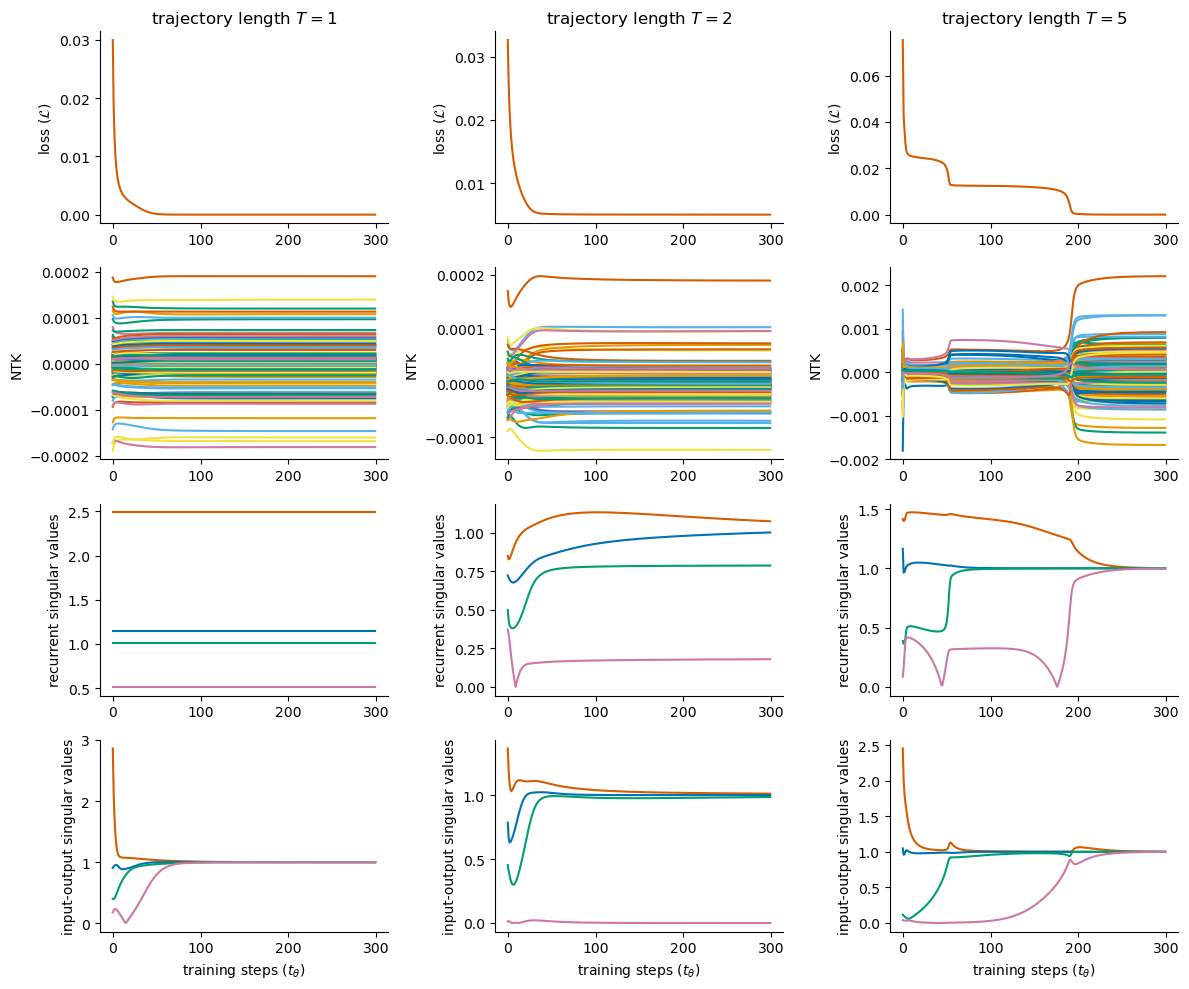

In [34]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()
fig = plt.figure(figsize=(12,10), layout='constrained')
mosaic = """
abc
def
ghi
jkl
"""
    
axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1])
        
axd['a'].plot(traj_1_tape.loss[seed], color=blind_colors[0])
axd['a'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['a'].set_title(r'trajectory length $T=1$')
axd['b'].plot(traj_2_tape.loss[seed], color=blind_colors[0])
axd['b'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['b'].set_title(r'trajectory length $T=2$')
axd['c'].plot(traj_5_tape.loss[seed], color=blind_colors[0])
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['c'].set_title(r'trajectory length $T=5$')
    
axd['d'].plot(traj_1_tape.NTK[seed].reshape(int(traj_1_args.num_epochs/traj_1_args.log_every_e_epoch), traj_1_args.num_samples*traj_1_args.output_size*traj_1_args.num_samples*traj_1_args.output_size)[:,:200])
axd['d'].set_ylabel('NTK')
axd['e'].plot(traj_2_tape.NTK[seed].reshape(int(traj_2_args.num_epochs/traj_2_args.log_every_e_epoch), traj_2_args.num_samples*traj_2_args.output_size*traj_2_args.num_samples*traj_2_args.output_size)[:,:200])
axd['e'].set_ylabel('NTK')
axd['f'].plot(traj_5_tape.NTK[seed].reshape(int(traj_5_args.num_epochs/traj_5_args.log_every_e_epoch), traj_5_args.num_samples*traj_5_args.output_size*traj_5_args.num_samples*traj_5_args.output_size)[:,:200])
axd['f'].set_ylabel('NTK')

axd['g'].plot(traj_1_tape.recurrent_modes[seed])
axd['g'].set_ylabel(r'recurrent singular values')
# axd['h'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['h'].plot(traj_2_tape.recurrent_modes[seed])
axd['h'].set_ylabel(r'recurrent singular values')
# axd['i'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['i'].plot(traj_5_tape.recurrent_modes[seed])
axd['i'].set_ylabel(r'recurrent singular values')
axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))
    
# axd['j'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['j'].plot(traj_1_tape.input_output_modes[seed])
axd['j'].set_ylabel(r'input-output singular values')
axd['j'].set_xlabel(r'training steps ($t_\theta$)')
# axd['k'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['k'].plot(traj_2_tape.input_output_modes[seed])
axd['k'].set_ylabel(r'input-output singular values')
axd['k'].set_xlabel(r'training steps ($t_\theta$)')
# axd['l'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['l'].plot(traj_5_tape.input_output_modes[seed])
axd['l'].set_ylabel(r'input-output singular values')
axd['l'].set_xlabel(r'training steps ($t_\theta$)')

fig.tight_layout()
# fig.savefig('paper_figs/rich_lazy_constant.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/rich_lazy_constant.png', dpi=300, transparent=True)

In [14]:
def kernel_distance(A,B):
    # Extract matrices K_t1 and K_t2
    K_t1 = A
    K_t2 = B
    # Compute the Frobenius inner product
    inner_product = np.sum(K_t1 * K_t2)
    # Compute the Frobenius norms
    norm_t1 = np.linalg.norm(K_t1, 'fro')
    norm_t2 = np.linalg.norm(K_t2, 'fro')
    # Compute the similarity measure
    S_t1_t2 = 1 - inner_product / (norm_t1 * norm_t2)
    return S_t1_t2

In [36]:
# Computes the kernel distance between the first and last epoch
reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
    int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
    traj_1_args.num_samples * traj_1_args.output_size,
    traj_1_args.num_samples * traj_1_args.output_size
)
KD_traj_1 = kernel_distance(reshaped_NTK_3D_traj_1[0,:,:],reshaped_NTK_3D_traj_1[-1,:,:])
print('KD-traj_2')
print(KD_traj_1)
reshaped_NTK_3D_traj_2 = traj_2_tape.NTK[seed].reshape(
    int(traj_2_args.num_epochs / traj_2_args.log_every_e_epoch),
    traj_2_args.num_samples * traj_2_args.output_size,
    traj_2_args.num_samples * traj_2_args.output_size
)
KD_traj_2 = kernel_distance(reshaped_NTK_3D_traj_2[0,:,:], reshaped_NTK_3D_traj_2[-1,:,:])
print('KD-traj_2')
print(KD_traj_2)
reshaped_NTK_3D_traj_5 = traj_5_tape.NTK[seed].reshape(
    int(traj_5_args.num_epochs / traj_5_args.log_every_e_epoch),
    traj_5_args.num_samples * traj_5_args.output_size,
    traj_5_args.num_samples * traj_5_args.output_size
)
KD_traj_5 = kernel_distance(reshaped_NTK_3D_traj_5[0,:,:], reshaped_NTK_3D_traj_5[-1,:,:])
print('KD-traj_5')
print(KD_traj_5)

KD-traj_2
0.05920875073006615
KD-traj_2
0.16929189802613442
KD-traj_5
0.7543518301230429


In [8]:
 from src import argparser
from src import simulate
from src import SV_configs
from src import utils
from src import linear_RNN
from pathlib import Path
import numpy as np
from types import SimpleNamespace
import matplotlib.pyplot as plt

In [9]:
traj_1_args = {
    'data_out_dir': 'data/',
    'results_out_dir': 'results/',
    'name': 'unaligned',
    'num_seeds': 1,  # to run over more seeds which need to be specified as arguments (see simulate.py for example)
    'override_load': False,
    'trajectory_length': 1,
    'num_samples': 50,
    'num_epochs': 30000,
    'lr': 0.1,
    'initialization_scale': 0.01,  # (variance of the 0-mean initialized weights when the network is unaligned)
    'input_size': 4,
    'hidden_size': 4,
    'output_size': 4,
    'S_config': ['constant', 'constant', 'constant', 'constant'],
    # data dynamics: constant (lambda_t=1-- overrides the lambda_0 argument), exponential (lambda_t=lambda^t), inverse-exponential (lambda_t=lambda^{T-t})
    'delta': [1, 1, 1, 1],  # data dynamics scaling-term (i.e., s_t = delta*lambda_t) for each SV dimension
    'lambda_0': [1, 2, 3, 4],  # data dynamics temporal-term
    'S_T': [1, 1, 1, 1],  # SV at last timestep (feedforward)
    'S_TeqS_t': True,  # whether SV at last timestep follows the data dynamics (if true, ignores S_T argument)
    'zero_balanced': True,  # if true, sets a=c at initialization (for aligned weights)
    'frozen_hidden_layer': False,  # freezes learning on recurrent layer
    'frozen_input_output': False,  # freezes learning on input-output layers
    'single_output_y': True,
    # only computes loss on y_T (ignores y_1 to y_{T-1}); code not compatible with the multi-output case at the moment
    'inout_mode_init': [0.49, 0.49, 0.49, 0.49, 0.49],
    # input-output mode initialization for each dimension (when weights are aligned and input-output are zero-balanced)
    'in_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    # input mode initialization for each dimension (when input-output weights are not zero-balanced)
    'out_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],  # output ""
    'rec_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],  # recurrent ""
    'num_SV': 4,  # num of SV dimensions (should be equal to input=hidden=output sizes)
    'aligned_student_weights': False,  # if False, random weights ; if True, aligned to SV data dynamics specified above
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 100,  # how many gradient steps until logging metrics
    'subsample_NTK': False  # whether to use a subsample of data when computing NTK
}
traj_1_args = SimpleNamespace(**traj_1_args)
traj_1_tape = utils.get_tape_module(traj_1_args)
traj_1_data_tape = utils.get_data_tape(traj_1_args)
seed = 0
utils.set_seeds(seed)

## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
traj_1_args.S = SV_configs.create_SV_trajectories(traj_1_args)
traj_1_data_tape = utils.generate_data_multiseed(traj_1_args, traj_1_data_tape, seed)

## example 2: generating data from a random unaligned teacher (or could be anything else)
# traj_1_X, traj_1_y, traj_1_t_W_x, traj_1_t_W_h, traj_1_t_W_y = generate_unaligned_teacher_data(traj_1_args, variance=0.1)
# traj_1_data_tape.X[seed] = traj_1_X
# traj_1_data_tape.y[seed] = traj_1_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
# traj_1_tape = utils.initialize_student_multiseed(traj_1_args, traj_1_data_tape, seed, traj_1_tape)

# example 2: unaligned RNN
traj_1_tape = utils.initialize_unaligned_student(traj_1_args, seed, traj_1_tape)

# --- model initialization, training, modes, NTK ---
traj_1_model = linear_RNN.LinearRNN_multiseed(traj_1_args, traj_1_tape, seed)
traj_1_model.train(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed])
traj_1_model.project_SVD_space(
    traj_1_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_1_model.compute_NTK(traj_1_data_tape.X[seed], traj_1_data_tape.y[seed], seed)
traj_1_tape = traj_1_model.tape

In [10]:
traj_2_args = {
    'data_out_dir': 'data/',
    'results_out_dir': 'results/',
    'name': 'unaligned',
    'num_seeds': 1,
    'override_load': False,
    'trajectory_length': 2,
    'num_samples': 50,
    'num_epochs': 30000,
    'lr': 0.1,
    'initialization_scale': 0.01,
    'input_size': 4,
    'hidden_size': 4,
    'output_size': 4,
    'S_config': ['constant', 'constant', 'constant', 'constant'],
    'delta': [1, 1, 1, 1],
    'lambda_0': [1, 2, 3, 4],
    'S_T': [1, 1, 1, 1],
    'S_TeqS_t': True,
    'zero_balanced': True,
    'frozen_hidden_layer': False,
    'frozen_input_output': False,
    'single_output_y': True,
    'inout_mode_init': [0.49, 0.49, 0.49, 0.49, 0.49],
    'in_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    'out_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    'rec_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    'num_SV': 4,
    'aligned_student_weights': False,
    'log_H': False,
    'log_y_hat': False,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 100,
    'subsample_NTK': False
}
traj_2_args = SimpleNamespace(**traj_2_args)
traj_2_tape = utils.get_tape_module(traj_2_args)
traj_2_data_tape = utils.get_data_tape(traj_2_args)
seed = 0
utils.set_seeds(seed)

## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
traj_2_args.S = SV_configs.create_SV_trajectories(traj_2_args)
traj_2_data_tape = utils.generate_data_multiseed(traj_2_args, traj_2_data_tape, seed)

## example 2: generating data from a random unaligned teacher (or could be anything else)
# traj_2_X, traj_2_y, traj_2_t_W_x, traj_2_t_W_h, traj_2_t_W_y = generate_unaligned_teacher_data(traj_2_args, variance=0.1)
# traj_2_data_tape.X[seed] = traj_2_X
# traj_2_data_tape.y[seed] = traj_2_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
# traj_2_tape = utils.initialize_student_multiseed(traj_2_args, traj_2_data_tape, seed, traj_2_tape)

# example 2: unaligned RNN
traj_2_tape = utils.initialize_unaligned_student(traj_2_args, seed, traj_2_tape)

# --- model initialization, training, modes, NTK ---
traj_2_model = linear_RNN.LinearRNN_multiseed(traj_2_args, traj_2_tape, seed)
traj_2_model.train(traj_2_data_tape.X[seed], traj_2_data_tape.y[seed])
traj_2_model.project_SVD_space(
    traj_2_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_2_model.compute_NTK(traj_2_data_tape.X[seed], traj_2_data_tape.y[seed], seed)
traj_2_tape = traj_2_model.tape

In [1]:
traj_5_args = {
    'data_out_dir': 'data/',
    'results_out_dir': 'results/',
    'name': 'unaligned',
    'num_seeds': 1,
    'override_load': False,
    'trajectory_length': 5,
    'num_samples': 50,
    'num_epochs': 30000,
    'lr': 0.1,
    'initialization_scale': 0.01,
    'input_size': 4,
    'hidden_size': 4,
    'output_size': 4,
    'S_config': ['constant', 'constant', 'constant', 'constant'],
    'delta': [1, 1, 1, 1],
    'lambda_0': [1, 1, 1, 1],
    'S_T': [1, 2, 3, 4],
    'S_TeqS_t': False,
    'zero_balanced': True,
    'frozen_hidden_layer': False,
    'frozen_input_output': False,
    'single_output_y': True,
    'inout_mode_init': [0.49, 0.49, 0.49, 0.49, 0.49],
    'in_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    'out_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    'rec_mode_init': [0.7, 0.7, 0.7, 0.7, 0.7],
    'num_SV': 4,
    'aligned_student_weights': False,
    'log_H': False,
    'log_y_hat': True,
    'compute_NTK': True,
    'nonlinear_RNN': False,
    'log_every_e_epoch': 100,
    'subsample_NTK': False
}
traj_5_args = SimpleNamespace(**traj_5_args)
traj_5_tape = utils.get_tape_module(traj_5_args)
traj_5_data_tape = utils.get_data_tape(traj_5_args)
seed = 0
utils.set_seeds(seed)

## --- generating tasks ----
## example 1: generating data from SV data dynamics specified in arguments
traj_5_args.S = SV_configs.create_SV_trajectories(traj_5_args)
traj_5_data_tape = utils.generate_data_multiseed(traj_5_args, traj_5_data_tape, seed)

## example 2: generating data from a random unaligned teacher (or could be anything else)
# traj_5_X, traj_5_y, traj_5_t_W_x, traj_5_t_W_h, traj_5_t_W_y = generate_unaligned_teacher_data(traj_5_args, variance=0.1)
# traj_5_data_tape.X[seed] = traj_5_X
# traj_5_data_tape.y[seed] = traj_5_y

## --- generating LRNN ----
## example 1: aligned RNN (NOTE: not set up to align to any given task; has to be generated from SV data dynamics specified in arguments)
## so don't combine aligned RNN + unaligned teacher unless new implementation
# traj_5_tape = utils.initialize_student_multiseed(traj_5_args, traj_5_data_tape, seed, traj_5_tape)

# example 2: unaligned RNN
traj_5_tape = utils.initialize_unaligned_student(traj_5_args, seed, traj_5_tape)

# --- model initialization, training, modes, NTK ---
traj_5_model = linear_RNN.LinearRNN_multiseed(traj_5_args, traj_5_tape, seed)
traj_5_model.train(traj_5_data_tape.X[seed], traj_5_data_tape.y[seed])
traj_5_model.project_SVD_space(
    traj_5_data_tape)  # computes modes for aligned network; computes SV for unaligned network
traj_5_model.compute_NTK(traj_5_data_tape.X[seed], traj_5_data_tape.y[seed], seed)
traj_5_tape = traj_5_model.tape


NameError: name 'SimpleNamespace' is not defined

In [ ]:
bc = utils.BlindColours()
blind_colors = bc.get_colours()
div_cmap = bc.get_div_cmap()
fig = plt.figure(figsize=(12, 10), layout='constrained')
mosaic = """
abc
def
ghi
jkl
"""

axd = fig.subplot_mosaic(mosaic)
for ax in axd.values():
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_prop_cycle('color', blind_colors[:-1])

axd['a'].plot(traj_1_tape.loss[seed], color=blind_colors[0])
axd['a'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['a'].set_title(r'trajectory length $T=1$')
axd['b'].plot(traj_2_tape.loss[seed], color=blind_colors[0])
axd['b'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['b'].set_title(r'trajectory length $T=2$')
axd['c'].plot(traj_5_tape.loss[seed], color=blind_colors[0])
axd['c'].set_ylabel(r'loss ($\mathcal{L}$)')
axd['c'].set_title(r'trajectory length $T=5$')

axd['d'].plot(traj_1_tape.NTK[seed].reshape(int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
                                            traj_1_args.num_samples * traj_1_args.output_size * traj_1_args.num_samples * traj_1_args.output_size)[
              :, :200])
axd['d'].set_ylabel('NTK')
axd['e'].plot(traj_2_tape.NTK[seed].reshape(int(traj_2_args.num_epochs / traj_2_args.log_every_e_epoch),
                                            traj_2_args.num_samples * traj_2_args.output_size * traj_2_args.num_samples * traj_2_args.output_size)[
              :, :200])
axd['e'].set_ylabel('NTK')
axd['f'].plot(traj_5_tape.NTK[seed].reshape(int(traj_5_args.num_epochs / traj_5_args.log_every_e_epoch),
                                            traj_5_args.num_samples * traj_5_args.output_size * traj_5_args.num_samples * traj_5_args.output_size)[
              :, :200])
axd['f'].set_ylabel('NTK')

axd['g'].plot(traj_1_tape.recurrent_modes[seed])
axd['g'].set_ylabel(r'recurrent singular values')
# axd['h'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['h'].plot(traj_2_tape.recurrent_modes[seed])
axd['h'].set_ylabel(r'recurrent singular values')
# axd['i'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['i'].plot(traj_5_tape.recurrent_modes[seed])
axd['i'].set_ylabel(r'recurrent singular values')
axd['i'].legend(frameon=False, bbox_to_anchor=(1, 0.5))

# axd['j'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['j'].plot(traj_1_tape.input_output_modes[seed])
axd['j'].set_ylabel(r'input-output singular values')
axd['j'].set_xlabel(r'training steps ($t_\theta$)')
# axd['k'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['k'].plot(traj_2_tape.input_output_modes[seed])
axd['k'].set_ylabel(r'input-output singular values')
axd['k'].set_xlabel(r'training steps ($t_\theta$)')
# axd['l'].plot([1.0]*300, color='gray', alpha=0.6, label='global solution')
axd['l'].plot(traj_5_tape.input_output_modes[seed])
axd['l'].set_ylabel(r'input-output singular values')
axd['l'].set_xlabel(r'training steps ($t_\theta$)')

fig.tight_layout()
# fig.savefig('paper_figs/rich_lazy_constant.svg', dpi=300, transparent=True)
# fig.savefig('paper_figs/rich_lazy_constant.png', dpi=300, transparent=True)

In [30]:
# Computes the kernel distance between the first and last epoch
reshaped_NTK_3D_traj_1 = traj_1_tape.NTK[seed].reshape(
    int(traj_1_args.num_epochs / traj_1_args.log_every_e_epoch),
    traj_1_args.num_samples * traj_1_args.output_size,
    traj_1_args.num_samples * traj_1_args.output_size
)
KD_traj_1 = kernel_distance(reshaped_NTK_3D_traj_1[0,:,:],reshaped_NTK_3D_traj_1[-1,:,:])
print('KD-traj_2')
print(KD_traj_1)
reshaped_NTK_3D_traj_2 = traj_2_tape.NTK[seed].reshape(
    int(traj_2_args.num_epochs / traj_2_args.log_every_e_epoch),
    traj_2_args.num_samples * traj_2_args.output_size,
    traj_2_args.num_samples * traj_2_args.output_size
)
KD_traj_2 = kernel_distance(reshaped_NTK_3D_traj_2[0,:,:], reshaped_NTK_3D_traj_2[-1,:,:])
print('KD-traj_2')
print(KD_traj_2)
reshaped_NTK_3D_traj_5 = traj_5_tape.NTK[seed].reshape(
    int(traj_5_args.num_epochs / traj_5_args.log_every_e_epoch),
    traj_5_args.num_samples * traj_5_args.output_size,
    traj_5_args.num_samples * traj_5_args.output_size
)
KD_traj_5 = kernel_distance(reshaped_NTK_3D_traj_5[0,:,:], reshaped_NTK_3D_traj_5[-1,:,:])
print('KD-traj_5')
print(KD_traj_5)

KD-traj_2
0.5279894783579124
KD-traj_2
0.8200011874322755
KD-traj_5
0.9578750725873931
